https://www.geeksforgeeks.org/nlp/building-a-basic-pdf-summarizer-llm-application-with-langchain/


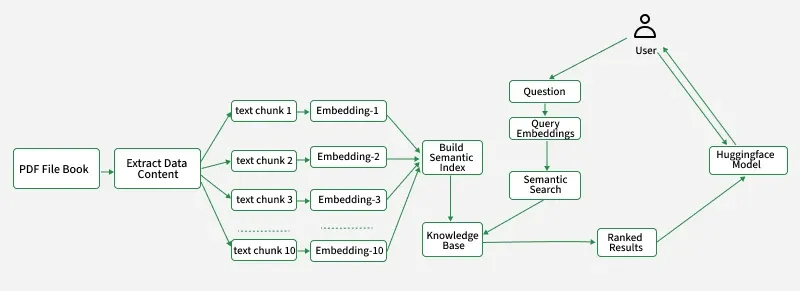

# 1. 패키지 설치

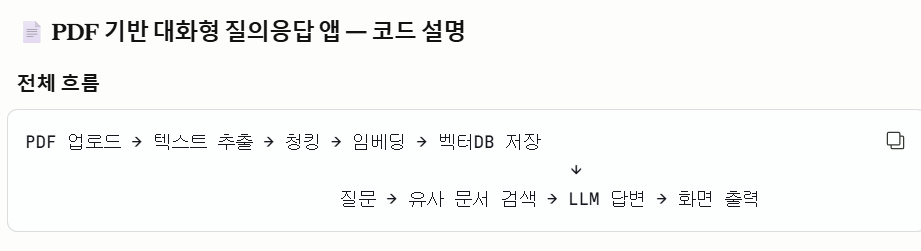

In [1]:
! uv pip install pymupdf

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 9ms


# 2. 라이브러리 임포트

In [2]:
import os
from dotenv import load_dotenv
from PyPDF2 import PdfReader
from langchain_text_splitters import CharacterTextSplitter
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.runnables.history import RunnableWithMessageHistory
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough, RunnableLambda
print('임포트 완료!')

임포트 완료!


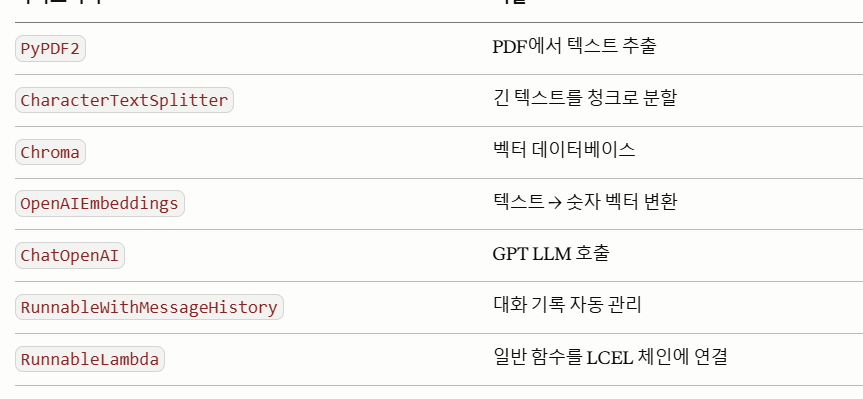

# 3. 환경변수 (API 키) 설정

In [3]:
load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')

if not api_key:
    print('❌ OPENAI_API_KEY를 찾을 수 없습니다. .env 파일을 확인하세요.')
elif not api_key.startswith('sk-'):
    print('⚠️ API 키 형식이 올바르지 않습니다. sk- 로 시작해야 합니다.')
elif api_key.strip() != api_key:
    print('⚠️ API 키 앞뒤에 공백이 있습니다. 제거해주세요.')
else:
    print('✅ API 키 확인 완료!')

✅ API 키 확인 완료!


# 4. PDF 텍스트 추출

여러 PDF를 받아 전체 텍스트를 하나의 문자열로 합칩니다.

In [4]:
def get_pdf_text(pdf_docs):
    """PDF 파일 리스트에서 텍스트를 추출합니다."""
    text = ""
    for pdf in pdf_docs:
        pdf_reader = PdfReader(pdf)
        for page in pdf_reader.pages:
            extracted_text = page.extract_text()
            if extracted_text:
                text += extracted_text + "\n"
    return text

# 5. 텍스트 청킹

In [5]:
def get_text_chunks(text):
    """텍스트를 일정 크기의 청크로 분할합니다."""
    text_splitter = CharacterTextSplitter(
        separator="\n",
        chunk_size=1000,
        chunk_overlap=200,
        length_function=len
    )
    return text_splitter.split_text(text)

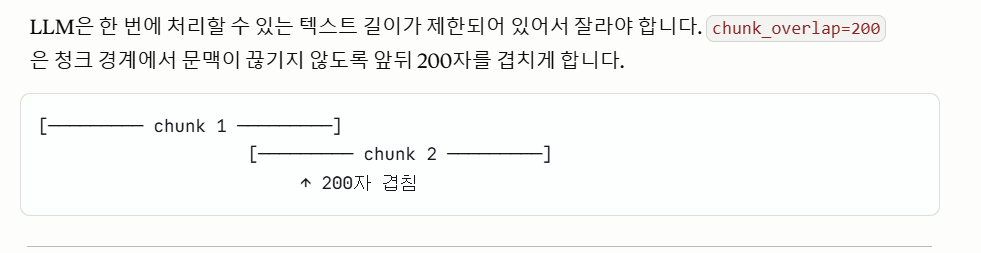

# 6. 임베딩 & 벡터스토어 생성

In [6]:
def get_vectorstore(text_chunks):
    # OpenAI 임베딩 모델 초기화
    # text-embedding-3-large: OpenAI 최신 고성능 임베딩 모델 (벡터 차원 3072)
    # text-embedding-3-small: 경량 버전 (벡터 차원 1536, 비용 절감)
    embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

    return Chroma.from_texts(
        texts=text_chunks,
        embedding=embeddings,
        persist_directory="chroma_db"  # 로컬 저장 경로 (필요 없으면 제거 가능)
    )

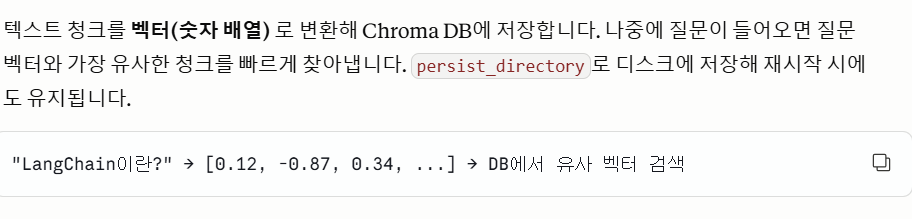

# 7. 대화 체인 설정 (LLM + Retriever + Memory)

In [7]:
# 세션별 대화 기록 저장소
store = {}

def get_session_history(session_id: str) -> InMemoryChatMessageHistory:
    """세션 ID로 대화 기록을 관리합니다."""
    if session_id not in store:
        store[session_id] = InMemoryChatMessageHistory()
    return store[session_id]


def get_conversation_chain(vectorstore):
    """벡터스토어 기반 대화 체인을 생성합니다."""
    # 1. LLM 초기화
    llm = ChatOpenAI(
        model_name="gpt-4.1-nano",
        temperature=0.7,
        max_tokens=512
    )

    # 2. Retriever 생성
    retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

    # 3. 프롬프트 템플릿
    prompt = ChatPromptTemplate.from_messages([
        ("system",
         "당신은 주어진 문서를 기반으로 질문에 답변하는 assistant입니다.\n"
         "반드시 아래 문서 내용에 근거하여 답변하세요.\n\n"
         "문서 내용:\n{context}"),
        MessagesPlaceholder(variable_name="chat_history"),
        ("human", "{question}")
    ])

    # 4. LCEL 체인 구성 (버그 수정: retriever가 question 문자열을 직접 받도록)
    #    RunnableWithMessageHistory는 input_messages_key로 지정된 키를
    #    그대로 chain에 전달하므로, chain 입력을 dict로 올바르게 매핑해야 함
    def retrieve_context(inputs):
        """inputs dict에서 question을 꺼내 retriever에 전달"""
        docs = retriever.invoke(inputs["question"])
        return "\n\n".join(doc.page_content for doc in docs)

    chain = (
        RunnablePassthrough.assign(context=RunnableLambda(retrieve_context))
        | prompt
        | llm
        | StrOutputParser()
    )

    # 5. 대화 기록 래핑
    conversation_chain = RunnableWithMessageHistory(
        chain,
        get_session_history,
        input_messages_key="question",
        history_messages_key="chat_history"
    )

    return conversation_chain

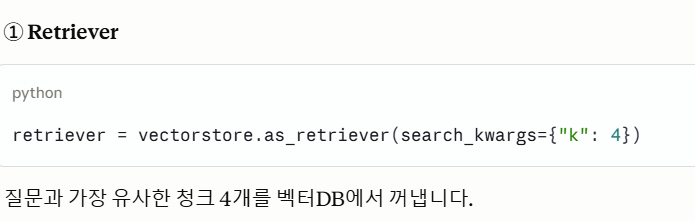 

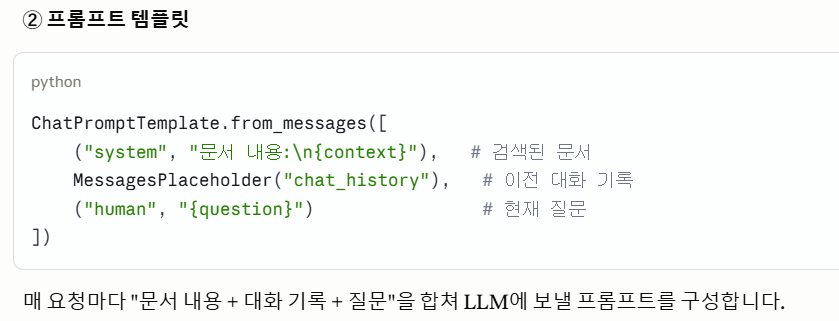 

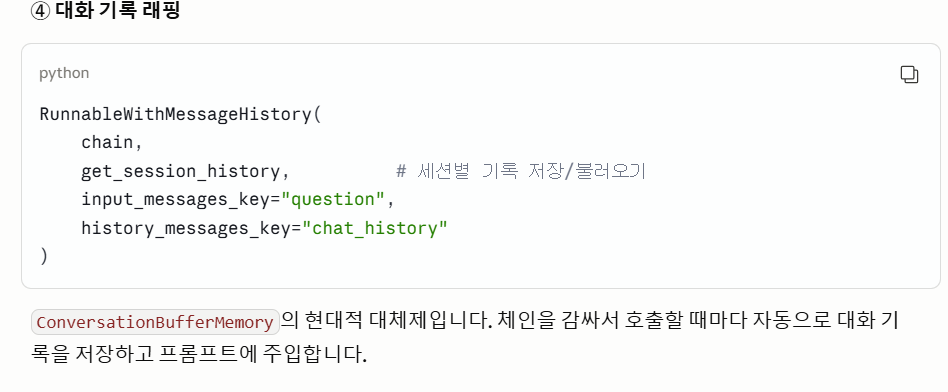

# 8. 사용자 입력 처리 함수

In [8]:
# 전역 conversation_chain (PDF 업로드 후 초기화)
conversation_chain = None


def handle_userinput(user_question, chat_history):
    """사용자 질문을 처리하고 대화 기록을 업데이트합니다."""
    if not user_question or not user_question.strip():
        return chat_history

    if conversation_chain is None:
        chat_history = chat_history or []
        chat_history.append({"role": "assistant",
                             "content": "⚠️ PDF를 먼저 업로드하고 [PDF 처리] 버튼을 눌러주세요."})
        return chat_history

    try:
        response = conversation_chain.invoke(
            {"question": user_question},
            config={"configurable": {"session_id": "gradio_session"}}
        )
        chat_history = chat_history or []
        chat_history.append({"role": "user",    "content": user_question})
        chat_history.append({"role": "assistant", "content": response})
    except Exception as e:
        chat_history.append({"role": "assistant", "content": f"❌ 오류 발생: {e}"})
    return chat_history

In [9]:
def process_pdfs(pdf_files):
    """PDF 파일들을 처리하고 conversation_chain을 초기화합니다."""
    global conversation_chain, store

    if not pdf_files:
        return "⚠️ PDF 파일을 먼저 업로드해주세요."

    try:
        # 기존 세션 기록 초기화
        store = {}

        raw_text = get_pdf_text(pdf_files)
        if not raw_text.strip():
            return "❌ PDF에서 텍스트를 추출할 수 없습니다. 스캔 PDF일 수 있습니다."

        text_chunks = get_text_chunks(raw_text)
        vectorstore = get_vectorstore(text_chunks)
        conversation_chain = get_conversation_chain(vectorstore)

        return f"✅ PDF 처리 완료! ({len(text_chunks)}개 청크 생성) 이제 질문하세요."
    except Exception as e:
        return f"❌ PDF 처리 중 오류: {e}"

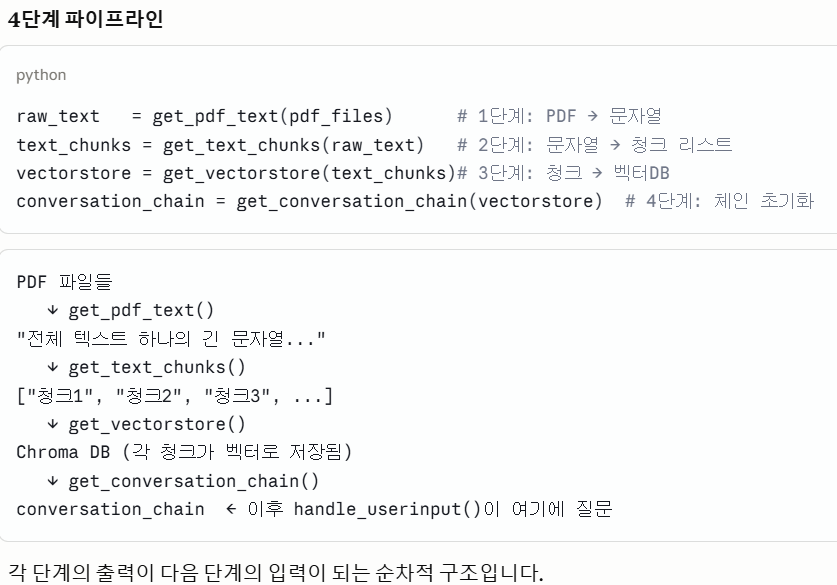

# 9. Gradio UI 실행

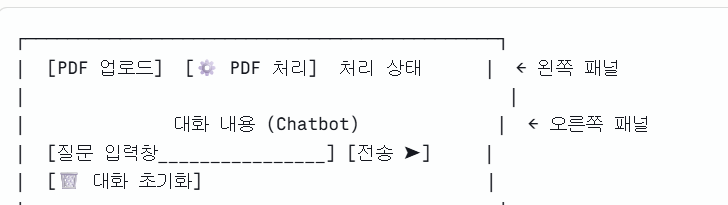

In [10]:
import gradio as gr

with gr.Blocks(title="PDF 질의응답") as demo:
    gr.Markdown("## 📄 PDF 기반 대화형 질의응답")
    gr.Markdown("PDF를 업로드하고 **[PDF 처리]** 버튼을 누른 뒤 질문하세요.")

    with gr.Row():
        with gr.Column(scale=1):
            # ── PDF 업로드 영역 ──
            pdf_upload = gr.File(
                label="📁 PDF 파일 업로드",
                file_types=[".pdf"],
                file_count="multiple"
            )
            process_btn = gr.Button("⚙️ PDF 처리", variant="primary")
            status_box = gr.Textbox(
                label="처리 상태",
                interactive=False,
                placeholder="PDF 처리 결과가 여기에 표시됩니다."
            )

        with gr.Column(scale=2):
            # ── 대화 영역 ──
            chatbot = gr.Chatbot(
                label="대화 내용",
                height=450,
                type="messages"   # Gradio 4.x 권장 포맷
            )
            with gr.Row():
                user_input = gr.Textbox(
                    label="질문 입력",
                    placeholder="질문을 입력하세요...",
                    scale=4
                )
                send_btn = gr.Button("전송 ➤", variant="primary", scale=1)
            clear_btn = gr.ClearButton(
                [chatbot, user_input],
                value="🗑️ 대화 초기화"
            )

    # ── 이벤트 연결 ──
    process_btn.click(
        fn=process_pdfs,
        inputs=[pdf_upload],
        outputs=[status_box]
    )

    send_btn.click(
        fn=handle_userinput,
        inputs=[user_input, chatbot],
        outputs=[chatbot]
    ).then(fn=lambda: "", outputs=[user_input])

    user_input.submit(
        fn=handle_userinput,
        inputs=[user_input, chatbot],
        outputs=[chatbot]
    ).then(fn=lambda: "", outputs=[user_input])

demo.launch(share=False)


* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


C:\Users\jino7\AppData\Local\Temp\ipykernel_19960\1471086310.py:18: LangChainDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  conversation_chain = get_conversation_chain(vectorstore)
